# 🌧️ Monthly Rainfall Analysis & Prediction
**A simple end-to-end data science project (Python, pandas, scikit-learn)**

## 1. Project goal
Understand rainfall patterns from 1982 to 2020 and build a simple model that predicts **next month's total rainfall**.

## 2. Data
Three monthly files:
| File | Column | Meaning |
|---|---|---|
| rainfall-monthly-total.csv | total_rainfall | Total rainfall in the month (mm) |
| rainfall-monthly-number-of-rain-days.csv | no_of_rainy_days | Number of rainy days |
| rainfall-monthly-highest-daily-total.csv | maximum_rainfall_in_a_day | Highest rainfall in a single day (mm) |

*(Units are assumed to be millimetres.)*

## 3. Steps
1. Load and merge data → 2. Check data quality → 3. Explore with charts → 4. Create features → 5. Train/test split → 6. Baselines → 7. Models → 8. Compare & conclude

## Step 1: Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

## Step 2: Load and merge the three files

In [2]:
# Put the CSV files in a folder called "data" next to this notebook (or in the same folder)
folder = Path("data") if Path("data/rainfall-monthly-total.csv").exists() else Path(".")

total = pd.read_csv(folder / "rainfall-monthly-total.csv")
days  = pd.read_csv(folder / "rainfall-monthly-number-of-rain-days.csv")
peak  = pd.read_csv(folder / "rainfall-monthly-highest-daily-total.csv")

# Merge on the 'month' column
df = total.merge(days, on="month").merge(peak, on="month")

# Rename columns to shorter names
df.columns = ["month", "total_mm", "rain_days", "max_daily_mm"]

# Convert text like '1982-01' into a real date
df["month"] = pd.to_datetime(df["month"])
df = df.sort_values("month").reset_index(drop=True)
df.head()

,month,total_mm,rain_days,max_daily_mm
0,1982-01-01,107.1,10,36.5
1,1982-02-01,27.8,5,9.4
2,1982-03-01,160.8,11,61.7
3,1982-04-01,157.0,14,45.1
4,1982-05-01,102.2,10,33.0


## Step 3: Check data quality

In [3]:
print("Shape:", df.shape)
print("Date range:", df["month"].min().date(), "to", df["month"].max().date())
print("Missing values:\n", df.isnull().sum())
print("Duplicate months:", df["month"].duplicated().sum())
df.describe()

Shape: (462, 4)
Date range: 1982-01-01 to 2020-06-01
Missing values:
 month           0
total_mm        0
rain_days       0
max_daily_mm    0
dtype: int64
Duplicate months: 0


,month,total_mm,rain_days,max_daily_mm
count,462,462.000000,462.000000,462.000000
mean,2001-03-17 00:15:35.064935,176.236580,13.958874,52.358225
min,1982-01-01 00:00:00,0.200000,1.000000,0.200000
25%,1991-08-08 18:00:00,89.025000,11.000000,30.625000
50%,2001-03-16 12:00:00,158.450000,14.000000,43.450000
75%,2010-10-24 06:00:00,237.950000,18.000000,63.150000
max,2020-06-01 00:00:00,765.900000,27.000000,216.200000
std,NaN,113.296793,4.947494,35.685122


**Observation:** the data is clean — no missing values and no duplicate months, so no cleaning is needed.
A quick logic check follows: the highest single-day rainfall can never be larger than the monthly total.

In [4]:
print("Rows where max daily > monthly total:", (df["max_daily_mm"] > df["total_mm"]).sum())

Rows where max daily > monthly total: 0


## Step 4: Add year and month columns

In [5]:
df["year"] = df["month"].dt.year
df["month_num"] = df["month"].dt.month
df.head()

,month,total_mm,rain_days,max_daily_mm,year,month_num
0,1982-01-01,107.1,10,36.5,1982,1
1,1982-02-01,27.8,5,9.4,1982,2
2,1982-03-01,160.8,11,61.7,1982,3
3,1982-04-01,157.0,14,45.1,1982,4
4,1982-05-01,102.2,10,33.0,1982,5


## Step 5: Exploratory Data Analysis (EDA)

### 5.1 Rainfall over time

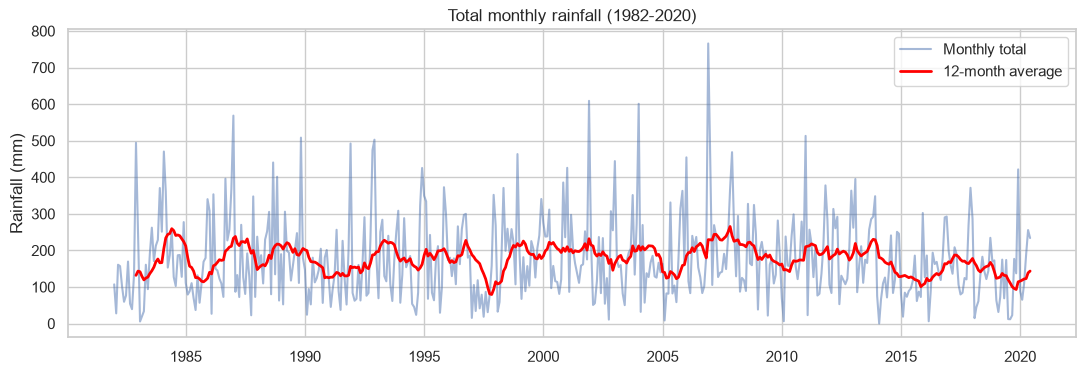

In [6]:
plt.figure(figsize=(13, 4))
plt.plot(df["month"], df["total_mm"], alpha=0.5, label="Monthly total")
plt.plot(df["month"], df["total_mm"].rolling(12).mean(), color="red", linewidth=2, label="12-month average")
plt.title("Total monthly rainfall (1982-2020)")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.show()

**Observation:** rainfall goes up and down every year (a seasonal pattern). The red 12-month average stays fairly flat, so there is no big long-term increase or decrease.

### 5.2 Which months are wettest?

,total_mm,rain_days,max_daily_mm
month_num,,,
1,226.0,13.4,74.5
2,104.7,8.3,38.7
3,160.3,12.2,47.6
4,153.0,14.4,45.7
5,165.8,14.0,48.5
6,134.3,12.9,43.6
7,146.3,13.3,40.5
8,147.1,13.7,49.2
9,145.7,13.1,45.1


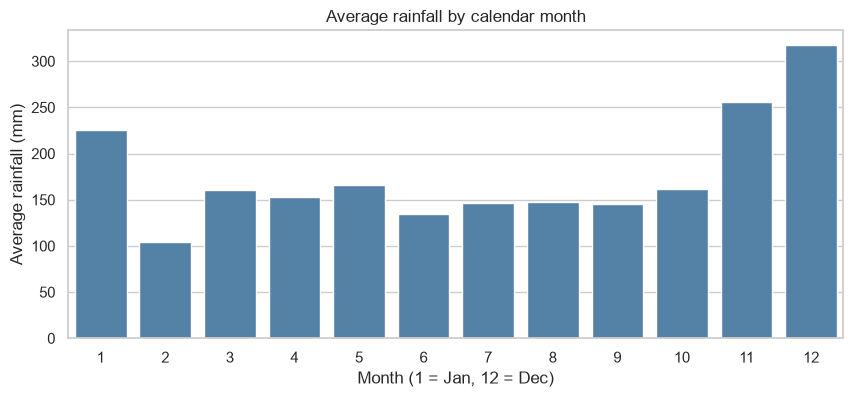

Wettest month: 12 | Driest month: 2


In [7]:
monthly_avg = df.groupby("month_num")[["total_mm", "rain_days", "max_daily_mm"]].mean().round(1)
display(monthly_avg)

plt.figure(figsize=(10, 4))
sns.barplot(x=monthly_avg.index, y=monthly_avg["total_mm"], color="steelblue")
plt.title("Average rainfall by calendar month")
plt.xlabel("Month (1 = Jan, 12 = Dec)")
plt.ylabel("Average rainfall (mm)")
plt.show()

print("Wettest month:", monthly_avg["total_mm"].idxmax(), "| Driest month:", monthly_avg["total_mm"].idxmin())

### 5.3 How much does rainfall vary within each month?

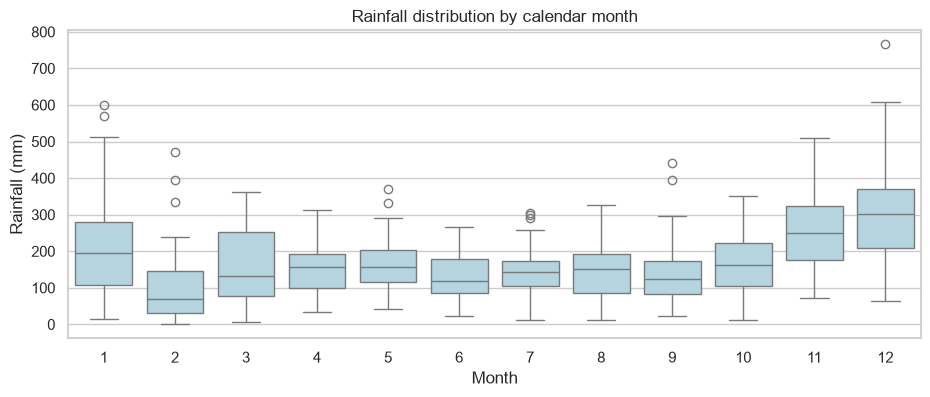

In [8]:
plt.figure(figsize=(11, 4))
sns.boxplot(data=df, x="month_num", y="total_mm", color="lightblue")
plt.title("Rainfall distribution by calendar month")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")
plt.show()

**Observation:** the same calendar month can be very different from year to year (big boxes and many dots above the whiskers). This tells us that predicting rainfall exactly will be hard.

### 5.4 Yearly total rainfall

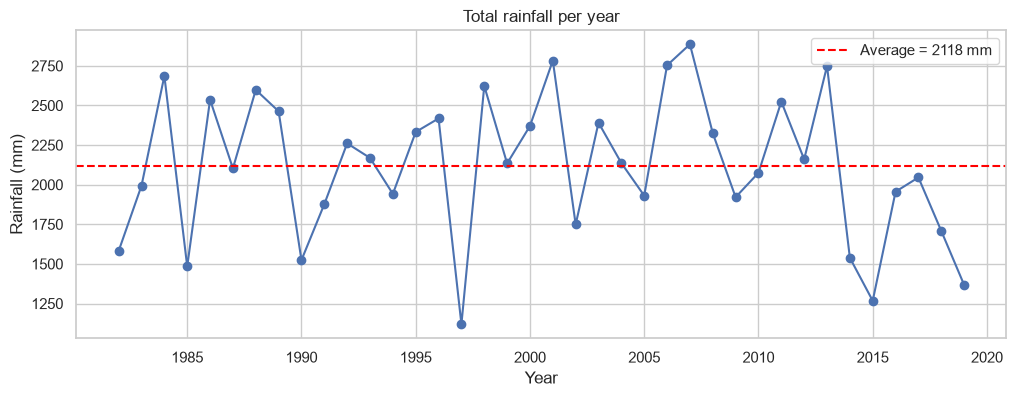

Wettest year: 2007 (2886 mm)
Driest year: 1997 (1119 mm)


In [9]:
yearly = df[df["year"] < 2020].groupby("year")["total_mm"].sum()   # 2020 is incomplete, so we skip it

plt.figure(figsize=(12, 4))
plt.plot(yearly.index, yearly.values, marker="o")
plt.axhline(yearly.mean(), color="red", linestyle="--", label=f"Average = {yearly.mean():.0f} mm")
plt.title("Total rainfall per year")
plt.xlabel("Year"); plt.ylabel("Rainfall (mm)")
plt.legend()
plt.show()

print("Wettest year:", yearly.idxmax(), f"({yearly.max():.0f} mm)")
print("Driest year:", yearly.idxmin(), f"({yearly.min():.0f} mm)")

### 5.5 Relationship between the variables

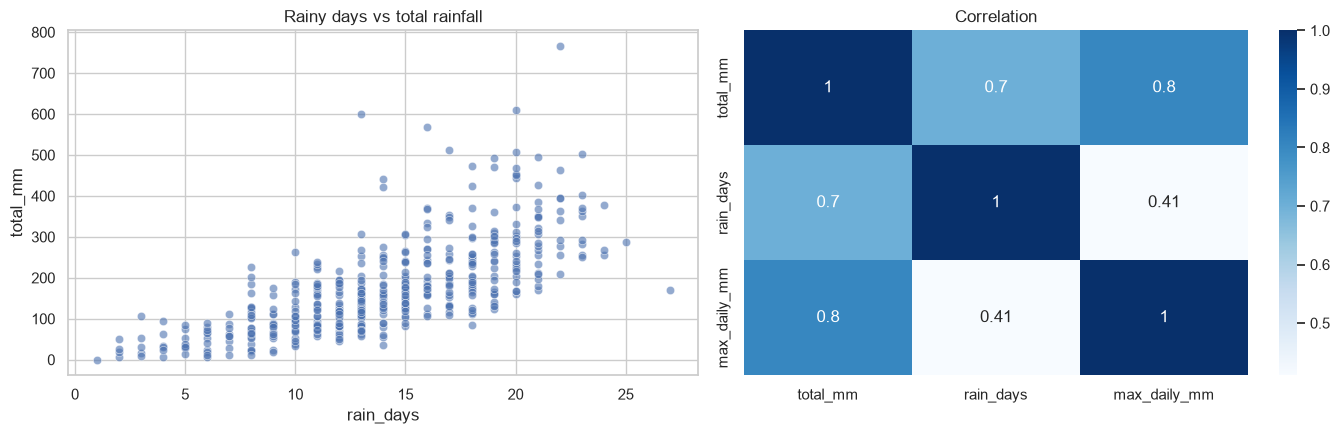

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.scatterplot(data=df, x="rain_days", y="total_mm", ax=axes[0], alpha=0.6)
axes[0].set_title("Rainy days vs total rainfall")

sns.heatmap(df[["total_mm", "rain_days", "max_daily_mm"]].corr(), annot=True, cmap="Blues", ax=axes[1])
axes[1].set_title("Correlation")
plt.tight_layout()
plt.show()

**Observation:** more rainy days and heavier single days both go with higher monthly totals (positive correlations).

## Step 6: Create features for prediction
We want to predict **this month's rainfall using information we already know**:
- the **month of the year** (captures the season)
- **last month's** rainfall, rainy days and highest daily rain
- rainfall **in the same month last year**
- the **average of the last 3 months**

`shift(1)` moves values down by one row, so each row sees only *past* data (this avoids data leakage).

In [11]:
data = df.copy()

data["total_last_month"]   = data["total_mm"].shift(1)
data["days_last_month"]    = data["rain_days"].shift(1)
data["max_last_month"]     = data["max_daily_mm"].shift(1)
data["total_last_year"]    = data["total_mm"].shift(12)
data["avg_last_3_months"]  = data["total_mm"].shift(1).rolling(3).mean()

# Turn month number into 12 yes/no columns (one-hot encoding)
month_dummies = pd.get_dummies(data["month_num"], prefix="month", dtype=int)
data = pd.concat([data, month_dummies], axis=1)

# Remove the first rows that have no history
data = data.dropna().reset_index(drop=True)

feature_cols = ["total_last_month", "days_last_month", "max_last_month",
                "total_last_year", "avg_last_3_months"] + list(month_dummies.columns)
print("Number of features:", len(feature_cols))
print("Rows available:", len(data))
data[["month", "total_mm"] + feature_cols[:5]].head()

Number of features: 17
Rows available: 450


,month,total_mm,total_last_month,days_last_month,max_last_month,total_last_year,avg_last_3_months
0,1983-01-01,246.0,494.1,21.0,109.0,107.1,222.466667
1,1983-02-01,5.6,246.0,18.0,43.2,27.8,291.366667
2,1983-03-01,18.6,5.6,2.0,5.1,160.8,248.566667
3,1983-04-01,33.6,18.6,2.0,18.3,157.0,90.066667
4,1983-05-01,160.8,33.6,4.0,21.3,102.2,19.266667


## Step 7: Train / test split
This is time-series data, so we **do not shuffle**. We train on the past and test on the most recent **5 years (60 months)**.

In [12]:
test_size = 60
train = data.iloc[:-test_size]
test  = data.iloc[-test_size:]

X_train, y_train = train[feature_cols], train["total_mm"]
X_test,  y_test  = test[feature_cols],  test["total_mm"]

print("Train:", train["month"].min().date(), "to", train["month"].max().date(), f"({len(train)} months)")
print("Test: ", test["month"].min().date(),  "to", test["month"].max().date(),  f"({len(test)} months)")

Train: 1983-01-01 to 2015-06-01 (390 months)
Test:  2015-07-01 to 2020-06-01 (60 months)


## Step 8: Baselines (simple rules to beat)
A model is only useful if it beats simple common-sense rules:
1. **Last month's rainfall** — predict the same as last month.
2. **Seasonal average** — predict the average rainfall of that calendar month in the training data.

In [13]:
def evaluate(name, y_true, y_pred):
    return {"Model": name,
            "MAE (mm)":  round(mean_absolute_error(y_true, y_pred), 1),
            "RMSE (mm)": round(np.sqrt(mean_squared_error(y_true, y_pred)), 1),
            "R2":        round(r2_score(y_true, y_pred), 3)}

results = []

# Baseline 1: same as last month
pred_last_month = X_test["total_last_month"]
results.append(evaluate("Baseline: last month", y_test, pred_last_month))

# Baseline 2: seasonal average from training data
season_avg = train.groupby("month_num")["total_mm"].mean()
pred_season = test["month_num"].map(season_avg)
results.append(evaluate("Baseline: seasonal average", y_test, pred_season))

pd.DataFrame(results)

,Model,MAE (mm),RMSE (mm),R2
0,Baseline: last month,74.7,103.6,-0.402
1,Baseline: seasonal average,67.6,82.8,0.106


## Step 9: Train machine learning models

In [14]:
# Model 1: Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)
results.append(evaluate("Linear Regression", y_test, pred_lr))

# Model 2: Random Forest
rf = RandomForestRegressor(n_estimators=200, max_depth=5, min_samples_leaf=5, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
results.append(evaluate("Random Forest", y_test, pred_rf))

results_df = pd.DataFrame(results).set_index("Model")
results_df

,MAE (mm),RMSE (mm),R2
Model,,,
Baseline: last month,74.7,103.6,-0.402
Baseline: seasonal average,67.6,82.8,0.106
Linear Regression,65.3,80.2,0.159
Random Forest,62.6,76.7,0.231


## Step 10: Compare models
**MAE** = average error in mm (lower is better). **RMSE** punishes big mistakes more. **R²** = how much variation is explained (1 = perfect, 0 = no better than predicting the overall average).

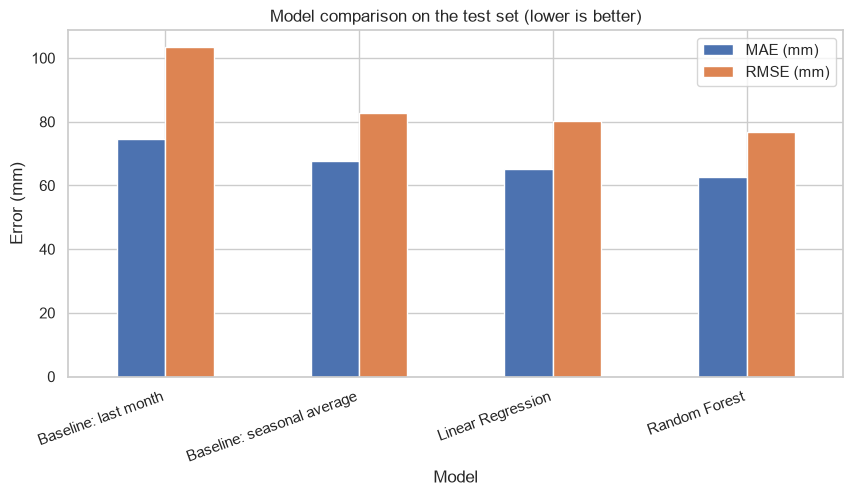

Lowest MAE: Random Forest


In [15]:
results_df[["MAE (mm)", "RMSE (mm)"]].plot(kind="bar", figsize=(10, 4.5))
plt.title("Model comparison on the test set (lower is better)")
plt.ylabel("Error (mm)")
plt.xticks(rotation=20, ha="right")
plt.show()

best = results_df["MAE (mm)"].idxmin()
print("Lowest MAE:", best)

### Actual vs predicted (test period)

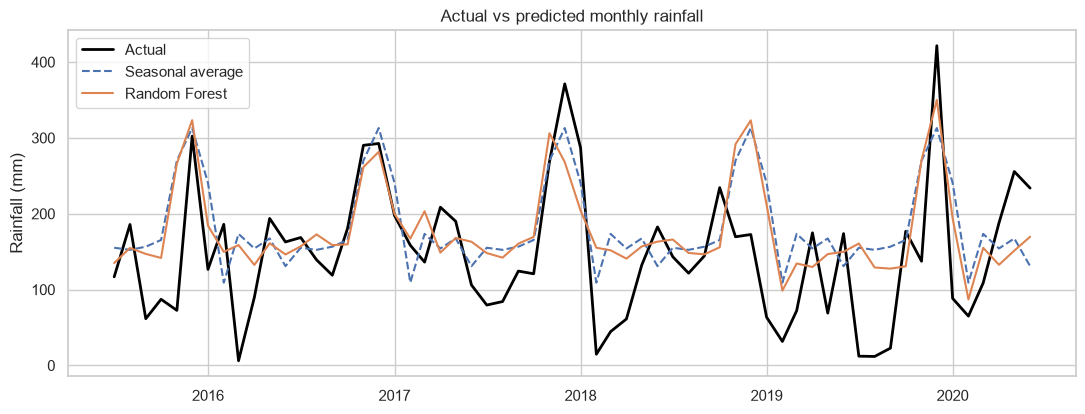

In [16]:
plt.figure(figsize=(13, 4.5))
plt.plot(test["month"], y_test.values, label="Actual", color="black", linewidth=2)
plt.plot(test["month"], pred_season.values, label="Seasonal average", linestyle="--")
plt.plot(test["month"], pred_rf, label="Random Forest")
plt.title("Actual vs predicted monthly rainfall")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.show()

### Which features matter most? (Random Forest)

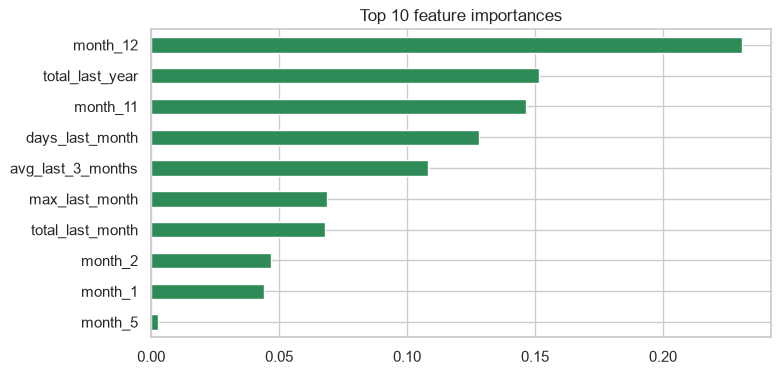

In [17]:
importance = pd.Series(rf.feature_importances_, index=feature_cols).sort_values().tail(10)
importance.plot(kind="barh", figsize=(8, 4), color="seagreen")
plt.title("Top 10 feature importances")
plt.show()

### Prediction errors

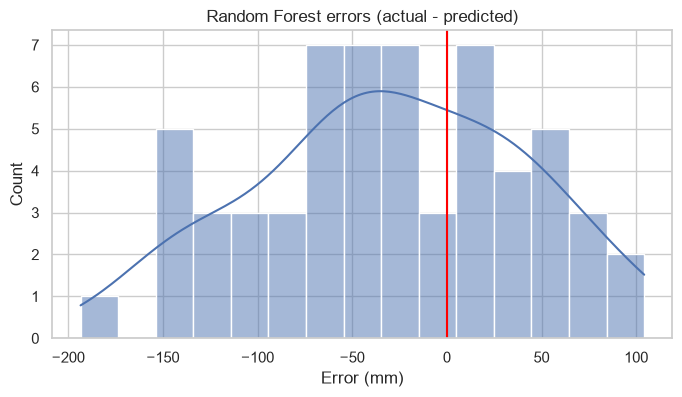

,month,total_mm,predicted,error
394,2015-11-01,72.6,266.1,-193.5
398,2016-03-01,6.2,158.6,-152.4
431,2018-12-01,172.6,323.1,-150.5
438,2019-07-01,12.2,160.7,-148.5
432,2019-01-01,63.6,211.6,-148.0


In [18]:
errors = y_test.values - pred_rf
plt.figure(figsize=(8, 4))
sns.histplot(errors, bins=15, kde=True)
plt.axvline(0, color="red")
plt.title("Random Forest errors (actual - predicted)")
plt.xlabel("Error (mm)")
plt.show()

big = test.assign(predicted=pred_rf.round(1), error=errors.round(1)).sort_values("error", key=abs, ascending=False)
big[["month", "total_mm", "predicted", "error"]].head(5)

**Observation:** the biggest mistakes happen in months that turn out very different from what is normal for that season (for example, an unusually dry month in the wet season). The model predicts a "typical" amount, so it cannot anticipate these surprises.

## Step 11: Predict next month (July 2020)

In [19]:
last = df.tail(12).reset_index(drop=True)          # most recent 12 months of real data
next_month = df["month"].max() + pd.DateOffset(months=1)

row = {
    "total_last_month":  df["total_mm"].iloc[-1],
    "days_last_month":   df["rain_days"].iloc[-1],
    "max_last_month":    df["max_daily_mm"].iloc[-1],
    "total_last_year":   df["total_mm"].iloc[-12],
    "avg_last_3_months": df["total_mm"].iloc[-3:].mean(),
}
for m in range(1, 13):
    row[f"month_{m}"] = 1 if m == next_month.month else 0

X_next = pd.DataFrame([row])[feature_cols]
print(f"Predicted rainfall for {next_month:%B %Y}:")
print(f"  Random Forest:    {rf.predict(X_next)[0]:.0f} mm")
print(f"  Linear Regression: {lr.predict(X_next)[0]:.0f} mm")
print(f"  Seasonal average: {df[df['month_num'] == next_month.month]['total_mm'].mean():.0f} mm")

Predicted rainfall for July 2020:
  Random Forest:    209 mm
  Linear Regression: 179 mm
  Seasonal average: 146 mm


## Step 12: Save results

In [20]:
out = test[["month", "total_mm"]].copy()
out["pred_seasonal_avg"] = pred_season.values
out["pred_linear_reg"]   = pred_lr
out["pred_random_forest"] = pred_rf
out.round(1).to_csv("test_predictions.csv", index=False)
results_df.to_csv("model_results.csv")
print("Saved: test_predictions.csv, model_results.csv")

Saved: test_predictions.csv, model_results.csv


## Step 13: Conclusion (generated from the results above)

In [21]:
from IPython.display import Markdown
r = results_df
best = r["MAE (mm)"].idxmin()
gap = r.loc["Baseline: seasonal average", "MAE (mm)"] - r.loc[best, "MAE (mm)"]
display(Markdown(f'''
**Findings**
- Rainfall has a clear **yearly pattern**: month {monthly_avg["total_mm"].idxmax()} is the wettest on average and month {monthly_avg["total_mm"].idxmin()} the driest.
- Rainfall in the same calendar month changes a lot from year to year, so it is **hard to predict exactly**.
- More rainy days and heavier single days both go with higher monthly totals.
- There is **no strong long-term trend** in yearly rainfall.

**Model results (last 5 years)**
- Best model by MAE: **{best}** (MAE {r.loc[best, "MAE (mm)"]} mm, R² {r.loc[best, "R2"]}).
- Seasonal-average baseline: MAE {r.loc["Baseline: seasonal average", "MAE (mm)"]} mm.
- The best model improves on the seasonal-average baseline by only **{gap:.1f} mm** on average, so the machine-learning models add **limited value** over simply knowing the season.
'''))


**Findings**
- Rainfall has a clear **yearly pattern**: month 12 is the wettest on average and month 2 the driest.
- Rainfall in the same calendar month changes a lot from year to year, so it is **hard to predict exactly**.
- More rainy days and heavier single days both go with higher monthly totals.
- There is **no strong long-term trend** in yearly rainfall.

**Model results (last 5 years)**
- Best model by MAE: **Random Forest** (MAE 62.6 mm, R² 0.231).
- Seasonal-average baseline: MAE 67.6 mm.
- The best model improves on the seasonal-average baseline by only **5.0 mm** on average, so the machine-learning models add **limited value** over simply knowing the season.
